# Praktikum 3 : DBSCAN data kafe

In [1]:
import pandas as pd
df = pd.read_csv('../../dataset_pbl/cafes.csv')
X = df[['latitude', 'longitude']].to_numpy()
labels_true = pd.factorize(df['source_query'].fillna('Tidak tersedia'))[0]
from sklearn.preprocessing import StandardScaler
X = StandardScaler().fit_transform(X)

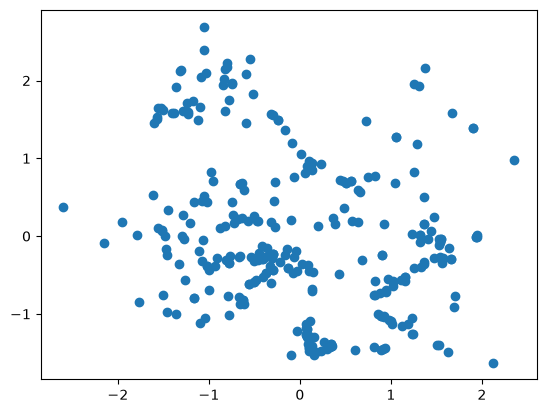

In [2]:
import matplotlib.pyplot as plt

plt.scatter(X[:, 0], X[:, 1])
plt.show()

In [3]:
# Compute DBSCAN

import numpy as np

from sklearn import metrics
from sklearn.cluster import DBSCAN

db = DBSCAN(eps=0.3, min_samples=10).fit(X)
labels = db.labels_

# Number of clusters in labels, ignoring noise if present.
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

print("Estimated number of clusters: %d" % n_clusters_)
print("Estimated number of noise points: %d" % n_noise_)

Estimated number of clusters: 7
Estimated number of noise points: 74


In [4]:
print(f"Homogeneity: {metrics.homogeneity_score(labels_true, labels):.3f}")  
print(f"Completeness: {metrics.completeness_score(labels_true, labels):.3f}")
print(f"V-measure: {metrics.v_measure_score(labels_true, labels):.3f}")
print(f"Adjusted Rand Index: {metrics.adjusted_rand_score(labels_true, labels):.3f}")
print(
    "Adjusted Mutual Information:"
    f" {metrics.adjusted_mutual_info_score(labels_true, labels):.3f}"
)
print('Silhouette:', metrics.silhouette_score(X, labels) if 1 < len(set(labels)) < len(X) else 'Tidak terdefinisi')

Homogeneity: 0.506
Completeness: 0.474
V-measure: 0.489
Adjusted Rand Index: 0.250
Adjusted Mutual Information: 0.466
Silhouette: 0.1996949399698051


Estimated number of clusters: 7


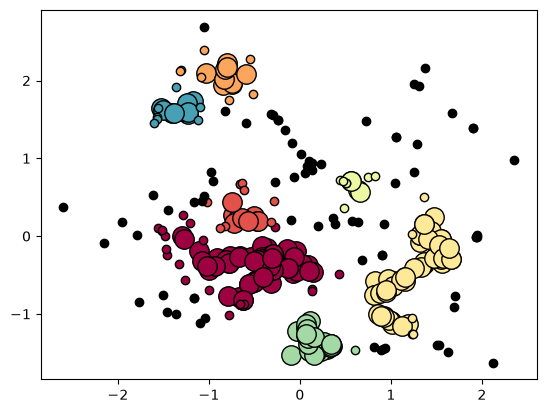

In [5]:
# Visualisasi Hasil Klasterisasi
unique_labels = set(labels)
core_samples_mask = np.zeros_like(labels, dtype=bool)
core_samples_mask[db.core_sample_indices_] = True

# colors = [plt.cm.Spectral(each) for each in (0, 1, len(unique_labels))]
colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
for k, col in zip(unique_labels, colors):
    if k == -1:
        # Black used for noise.
        col = [0, 0, 0, 1]

    class_member_mask = labels == k

    xy = X[class_member_mask & core_samples_mask]
    plt.plot(
        xy[:, 0],
        xy[:, 1],
        "o",
        markerfacecolor=tuple(col),
        markeredgecolor="k",
        markersize=14,
    )

    xy = X[class_member_mask & ~core_samples_mask]
    plt.plot(
        xy[:, 0],
        xy[:, 1],
        "o",
        markerfacecolor=tuple(col),
        markeredgecolor="k",
        markersize=6,
    )

print(f"Estimated number of clusters: {n_clusters_}")
plt.show()